# Industry Project: A Professional PyTorch Training Pipeline (Production-Style)

> **Who is this notebook for?** Someone who knows roughly what a neural network is (layers, loss, gradient descent), but has never written a training script the way a company would.
> You do **not** need the math from the other notebooks. Every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from the others in `05_Deep_Learning/`

| `01_neural_network_fundamentals`, `02_optimizers`, `03_cnn` ... | This notebook |
|---|---|
| Explain **how** layers, losses and optimizers work (math, from-scratch NumPy) | Shows **how a team actually trains** a PyTorch model that others can trust and reproduce |
| A training loop of 5 lines (`loss.backward(); optimizer.step()`) | A training loop with validation, LR schedule, gradient clipping, early stopping, checkpoints and resume |
| Report the final training accuracy | Sanity checks **before** training, an honest test set, **baselines**, confidence intervals and error analysis |
| Results change every run | Seeded, deterministic, and **resumable** after a crash with identical results |

Think of the other notebooks as *learning how the engine works*, and this notebook as *the checklist a professional pilot runs before, during and after every flight*.

---

### The business problem

You work for a company that processes **scanned paper forms** (think: bank cheques, postal codes, tax forms). Each form contains handwritten digits that clerks currently type in by hand.

- Manual entry costs about **$0.05 per digit** and is slow.
- A wrong digit that slips through (e.g. a wrong account number) costs about **$5** to fix later.
- The plan: a model reads every digit. **Confident** predictions are accepted automatically, **unsure** ones go to a human.

**Success means:** the neural network must (1) be clearly better than the simple model the team already has (logistic regression), (2) automate as many digits as possible while keeping the error rate of auto-accepted digits **below 0.5%**, and (3) be trained by a pipeline that anyone on the team can **re-run and get the same model**.

We use the scikit-learn **digits** dataset (1,797 scanned 8×8 handwritten digits, bundled with scikit-learn, so it works offline). It is small, so the whole notebook runs in a few minutes on a laptop CPU, but every technique is exactly what you would use on millions of images.

---

### The training workflow we will follow (inspired by Karpathy's *"A Recipe for Training Neural Networks"*)

```
 1. Become one with the data  ->  2. Honest split + normalisation fitted on train only
          |                                              |
 3. Dataset / DataLoader  ->  4. Model  ->  5. Sanity checks BEFORE training (loss @ init, overfit one batch)
                                                         |
 6. Training engine: AdamW + OneCycle LR + grad clipping + early stopping + checkpoints
          |
 7. Train + learning curves -> 8. Crash & resume -> 9. Test vs baselines -> 10. Seeds -> 11. Ship
```

### Table of Contents
1. Setup: imports, config, seeding and device
2. Become one with the data
3. Honest split and normalisation (fitted on train only)
4. `Dataset` and `DataLoader`
5. The model
6. Sanity checks before training
7. The training engine (one epoch, evaluation, early stopping, checkpoints)
8. The `fit()` function: AdamW + OneCycle + clipping + resume
9. Train the model and read the learning curves
10. Crash and resume: proving the pipeline is reproducible
11. Final evaluation on the test set against baselines
12. Error analysis and the business decision (auto-accept threshold)
13. How much do results depend on the seed?
14. Load the checkpoint like production does
15. Automated tests
16. GPUs, mixed precision and frameworks (Lightning, HF Trainer)
17. Summary, exercises and resources

---
## 1. Setup: imports, config, seeding and device

Three habits you will see in every professional training script:

1. **One config object.** Every hyperparameter (learning rate, batch size, epochs...) lives in one `dataclass`. The config is saved **inside every checkpoint**, so months later you know exactly how a model was trained.
2. **Seeding.** Neural network training is full of randomness (initial weights, data shuffling, dropout). Fixing the seeds makes runs repeatable, so that when a result changes you know it was *your change* and not luck.
3. **Device-agnostic code.** We write `device = "cuda" if available else "cpu"` once and move tensors with `.to(device)`. The *same* code then runs on a laptop CPU, a GPU server, or an Apple Silicon Mac.

In [1]:
# ---- Standard library ----
import copy                       # deep copies of model weights
import json                       # readable metadata files
import logging                    # professional status messages instead of print()
import math                       # math.log for the "expected initial loss"
import os                         # environment variables
import random                     # Python's own random generator (we seed it too)
import shutil                     # to clean up temporary folders
import tempfile                   # temporary folder for checkpoints (keeps the repo clean)
import time                       # timing epochs
import warnings                   # hide noisy library warnings in this tutorial
from dataclasses import dataclass, asdict, replace   # config container + helpers
from datetime import datetime, timezone              # timestamps in metadata
from pathlib import Path          # modern file paths

# ---- Third-party ----
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

from sklearn.datasets import load_digits
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("train")

# Tiny models train FASTEST on a single CPU thread (multi-threading overhead > the work per layer).
# For big models use more threads, e.g. torch.set_num_threads(os.cpu_count()).
torch.set_num_threads(1)
log.info("PyTorch %s | CUDA available: %s", torch.__version__, torch.cuda.is_available())


@dataclass(frozen=True)           # frozen = cannot be changed by accident halfway through the notebook
class TrainConfig:
    seed: int = 42                # one seed controls ALL randomness
    val_size: float = 0.20        # 20% of all data for validation (model selection, early stopping)
    test_size: float = 0.20       # 20% locked away for the final exam
    batch_size: int = 64          # images per gradient step
    max_epochs: int = 40          # upper limit; early stopping may stop sooner
    max_lr: float = 3e-3          # peak learning rate of the OneCycle schedule
    weight_decay: float = 1e-2    # AdamW regularisation (applied to weights, not to biases/norms)
    grad_clip_norm: float = 1.0   # gradient clipping threshold (protects against exploding gradients)
    dropout: float = 0.3          # dropout probability in the classifier head
    patience: int = 8             # early stopping: epochs without val-loss improvement before we stop
    use_amp: bool = False         # mixed precision; only useful on a GPU (see Section 16)
    num_workers: int = 0          # DataLoader worker processes (0 = main process; fine for small data)


CFG = TrainConfig()
print(CFG)

2026-10-21 16:30:23,379 | INFO | PyTorch 2.12.1+cpu | CUDA available: False


TrainConfig(seed=42, val_size=0.2, test_size=0.2, batch_size=64, max_epochs=40, max_lr=0.003, weight_decay=0.01, grad_clip_norm=1.0, dropout=0.3, patience=8, use_amp=False, num_workers=0)


### Seeding and determinism

`seed_everything` seeds **all** random number generators we use (Python, NumPy, PyTorch CPU and GPU).
`torch.use_deterministic_algorithms(True)` goes one step further: PyTorch will use only operations that give bit-identical results every time (and raise an error if an operation has no deterministic version).

> ⚠️ **What determinism does NOT promise.** The PyTorch docs say: *"Completely reproducible results are not guaranteed across PyTorch releases, individual commits, or different platforms."* So the same seed on a GPU vs a CPU, or after a library upgrade, may give slightly different numbers. That's why we also record library versions in the checkpoint, and why (Section 13) we check how much results move between seeds.

In [2]:
def seed_everything(seed: int) -> None:
    """Seed every random number generator we use, so runs are repeatable."""
    random.seed(seed)                       # Python's random module
    np.random.seed(seed)                    # NumPy's global generator
    torch.manual_seed(seed)                 # PyTorch CPU (and all GPUs)
    torch.cuda.manual_seed_all(seed)        # explicit for multi-GPU machines (no-op without CUDA)


def configure_determinism() -> None:
    """Ask PyTorch to use only deterministic algorithms (may be a bit slower on GPU)."""
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # required for deterministic cuBLAS on GPU
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False  # cuDNN autotuner picks algorithms non-deterministically


def get_device() -> torch.device:
    """Pick the best available hardware. The rest of the code never hard-codes 'cpu' or 'cuda'."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():   # Apple Silicon GPUs
        return torch.device("mps")
    return torch.device("cpu")


configure_determinism()
seed_everything(CFG.seed)
DEVICE = get_device()
log.info("Training on device: %s", DEVICE)

2026-10-21 16:30:27,290 | INFO | Training on device: cpu


---
## 2. Become one with the data

Karpathy's first rule: *"The first step to training a neural net is to not touch any neural net code at all and instead begin by thoroughly inspecting your data."*

In a company the scans would come from an object store (S3 / Azure Blob) plus a labels table, e.g.:

```python
# Real-life version (not run here):
# labels = pd.read_sql("SELECT scan_id, digit FROM labelled_digits", engine)
# images = [load_png(f"s3://forms-bucket/digits/{scan_id}.png") for scan_id in labels.scan_id]
```

Here we load the bundled dataset and check the four basics: **shape, value range, class balance, and what the images actually look like**. We also check for **exact duplicate images**: duplicates that land in both train and test make the test score look better than it really is.

In [3]:
digits = load_digits()                                   # bundled with scikit-learn, no download needed
images = digits.images.astype(np.float32)                # shape (n, 8, 8), pixel values 0..16
labels = digits.target.astype(np.int64)                  # the digit 0..9
CLASS_NAMES = [str(c) for c in digits.target_names]
NUM_CLASSES = len(CLASS_NAMES)

print(f"Images: {images.shape}  dtype={images.dtype}")
print(f"Pixel range: min={images.min():.0f}, max={images.max():.0f}  (scanner gives 0..16 ink levels)")
print("Images per class:", np.bincount(labels).tolist())

# Exact duplicates? Compare every image as a flat byte string.
flat = images.reshape(len(images), -1)
n_unique = len(np.unique(flat, axis=0))
print(f"Exact duplicate images: {len(images) - n_unique}")

Images: (1797, 8, 8)  dtype=float32
Pixel range: min=0, max=16  (scanner gives 0..16 ink levels)
Images per class: [178, 182, 177, 183, 181, 182, 181, 179, 174, 180]
Exact duplicate images: 0


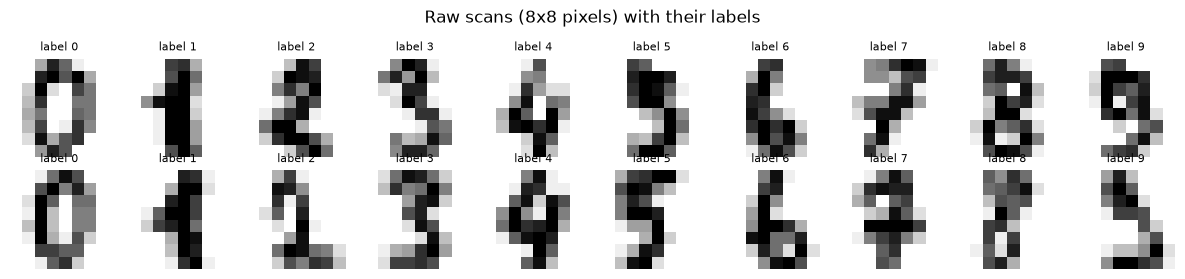

In [4]:
# Look at real examples: 2 per class. Do the labels look right? Are images upside down? Cropped?
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for digit in range(NUM_CLASSES):
    idx = np.where(labels == digit)[0][:2]                # first two examples of this digit
    for row in range(2):
        axes[row, digit].imshow(images[idx[row]], cmap="gray_r")
        axes[row, digit].set_title(f"label {digit}", fontsize=8)
        axes[row, digit].axis("off")
plt.suptitle("Raw scans (8x8 pixels) with their labels")
plt.tight_layout(); plt.show()

**What we learned:** the 10 classes are almost perfectly balanced (~180 each), pixel values are integers 0..16, and the images are tiny and blurry, so some digits (1 vs 7, 8 vs 9...) will be genuinely hard even for a human.

Because the classes are balanced, a model that guesses gets about **10% accuracy**, and its cross-entropy loss is about **ln(10) ≈ 2.30**. We will use that number in the sanity checks.

---
## 3. Honest split and normalisation (fitted on train only)

We split **once**, at the very start, into three parts:

| Part | Size | Used for |
|---|---|---|
| **train** | 60% | learning the weights |
| **validation** | 20% | choosing the epoch (early stopping), comparing settings |
| **test** | 20% | **one** final, honest number at the very end |

`stratify` keeps the same class mix in every part.

**Normalisation** (subtract the mean, divide by the standard deviation) makes training much easier. The mean and std must be computed **on the training set only**: if you include validation/test images, information about them leaks into training. The two numbers become part of the model: we save them in the checkpoint because the production service must apply *exactly* the same transformation.

In [5]:
# First split off the test set, then split the rest into train / validation
idx_all = np.arange(len(images))
idx_trainval, idx_test = train_test_split(idx_all, test_size=CFG.test_size,
                                          stratify=labels, random_state=CFG.seed)
val_fraction_of_rest = CFG.val_size / (1 - CFG.test_size)          # 0.20 / 0.80 = 25% of the remainder
idx_train, idx_val = train_test_split(idx_trainval, test_size=val_fraction_of_rest,
                                      stratify=labels[idx_trainval], random_state=CFG.seed)
print(f"train={len(idx_train)}  val={len(idx_val)}  test={len(idx_test)}")

# Normalisation statistics from the TRAINING images only
NORM_MEAN = float(images[idx_train].mean())
NORM_STD = float(images[idx_train].std())
print(f"Normalisation fitted on train: mean={NORM_MEAN:.3f}, std={NORM_STD:.3f}")

train=1077  val=360  test=360
Normalisation fitted on train: mean=4.904, std=6.027


---
## 4. `Dataset` and `DataLoader`

PyTorch separates data handling into two pieces:

- A **`Dataset`** knows how to return **one** example: `dataset[i] -> (image_tensor, label)`. This is where per-example preprocessing (normalisation, augmentation, reading a file from disk) lives.
- A **`DataLoader`** groups examples into **batches**, shuffles the training data every epoch and can load data in parallel worker processes.

Industry details worth copying:
- `shuffle=True` only for training. Validation/test order does not matter, and keeping it fixed makes debugging easier.
- A **seeded `torch.Generator`** controls the shuffle order, so it is reproducible and can be **saved and restored** in a checkpoint.
- `num_workers > 0` and `pin_memory=True` speed things up on GPUs with large datasets (images decoded from disk). With 1,000 tiny images in memory, `num_workers=0` is actually fastest. When you use workers, also pass `worker_init_fn` so each worker is seeded (see the PyTorch "Reproducibility" page).

In [6]:
class DigitsDataset(Dataset):
    """Returns (normalised image of shape [1, 8, 8], label) for one scan."""

    def __init__(self, images: np.ndarray, labels: np.ndarray, mean: float, std: float):
        # Convert once to tensors; add a "channel" dimension: CNNs expect [channels, height, width]
        self.x = torch.from_numpy((images - mean) / std).unsqueeze(1).float()
        self.y = torch.from_numpy(labels).long()

    def __len__(self) -> int:
        return len(self.y)                                  # number of examples

    def __getitem__(self, i: int):
        return self.x[i], self.y[i]                         # one (image, label) pair


def make_datasets(mean: float = NORM_MEAN, std: float = NORM_STD) -> dict:
    """Build the three datasets with the SAME normalisation (fitted on train)."""
    return {name: DigitsDataset(images[idx], labels[idx], mean, std)
            for name, idx in [("train", idx_train), ("val", idx_val), ("test", idx_test)]}


def make_loaders(datasets: dict, cfg: TrainConfig, generator: torch.Generator) -> dict:
    """Training loader shuffles with a seeded generator; evaluation loaders do not shuffle."""
    common = dict(batch_size=cfg.batch_size, num_workers=cfg.num_workers,
                  pin_memory=(DEVICE.type == "cuda"))        # pinned memory = faster CPU->GPU copies
    return {
        "train": DataLoader(datasets["train"], shuffle=True, generator=generator, **common),
        "val": DataLoader(datasets["val"], shuffle=False, **common),
        "test": DataLoader(datasets["test"], shuffle=False, **common),
    }


DATASETS = make_datasets()
demo_loaders = make_loaders(DATASETS, CFG, torch.Generator().manual_seed(CFG.seed))

# Karpathy: "visualise just before the net". Check the exact tensors the model will receive.
xb, yb = next(iter(demo_loaders["train"]))
print(f"batch x: shape={tuple(xb.shape)} dtype={xb.dtype} mean={xb.mean():.3f} std={xb.std():.3f}")
print(f"batch y: shape={tuple(yb.shape)} dtype={yb.dtype} first labels={yb[:10].tolist()}")

batch x: shape=(64, 1, 8, 8) dtype=torch.float32 mean=0.013 std=1.002
batch y: shape=(64,) dtype=torch.int64 first labels=[6, 1, 5, 7, 8, 6, 7, 4, 8, 9]


The batch has the shape the model expects (`[batch, channel, height, width]`), integer labels, and roughly mean 0 / std 1 after normalisation. Bugs in this step (wrong shape, labels shuffled separately from images, forgetting to normalise) are among the most common reasons a network "doesn't learn".

---
## 5. The model

Karpathy's advice is *"don't be a hero"*: start from a simple, well-known architecture. For small images that is a small **CNN**: two convolution blocks (convolution, batch normalisation, ReLU), a pooling layer, and a small fully connected **head** with dropout.

Two professional touches:
- Hyperparameters such as dropout come **from the config**, not hard-coded numbers.
- We count the **parameters**: it tells you the model size and (roughly) how much data it needs.

In [7]:
class DigitCNN(nn.Module):
    """Small CNN for 8x8 grayscale digits."""

    def __init__(self, num_classes: int = 10, dropout: float = 0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),   # 1 input channel -> 16 feature maps, 8x8
            nn.BatchNorm2d(16),                           # normalise activations, stabilises training
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # 16 -> 32 feature maps, still 8x8
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 8x8 -> 4x4
        )
        self.head = nn.Sequential(
            nn.Flatten(),                                 # [batch, 32, 4, 4] -> [batch, 512]
            nn.Dropout(dropout),                          # randomly zero features during training
            nn.Linear(32 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),                  # one raw score ("logit") per class
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.features(x))               # logits; softmax is applied inside the loss


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


model = DigitCNN(NUM_CLASSES, CFG.dropout).to(DEVICE)
print(model)
print(f"\nTrainable parameters: {count_parameters(model):,}")

DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

Trainable parameters: 71,850


---
## 6. Sanity checks before training

These checks take seconds and catch most bugs **before** you waste hours (or GPU dollars) on a broken run. They come straight from Karpathy's recipe:

1. **Loss at initialisation.** A freshly initialised classifier should be "equally unsure" about all classes, so its cross-entropy should be close to `-ln(1/10) = ln(10) ≈ 2.303`. If it is 10 or 50, the initialisation or the last layer is wrong.
2. **Gradients reach every parameter.** After one `backward()`, every trainable tensor should have a non-zero gradient. A layer with no gradient is "disconnected" (a common bug when you forget to use a layer in `forward`).
3. **Overfit one batch.** Train on a *single* batch of 32 images for ~100 steps. A working model + loss + optimizer must drive the loss to almost zero (it memorises them). If it cannot, there is a bug; no amount of data will fix it.
4. **Input-independent baseline.** Train briefly with all inputs set to zero. The model can then only learn the class frequencies, so it should get ~10% validation accuracy. Our real model must do much better; otherwise it is not using the images at all.

In [8]:
# Check 1: loss at initialisation
seed_everything(CFG.seed)
model = DigitCNN(NUM_CLASSES, CFG.dropout).to(DEVICE)
xb, yb = xb.to(DEVICE), yb.to(DEVICE)
initial_loss = F.cross_entropy(model(xb), yb)
expected = math.log(NUM_CLASSES)
print(f"Check 1  loss at init = {initial_loss.item():.3f}   expected ≈ ln({NUM_CLASSES}) = {expected:.3f}")

# Check 2: every parameter receives a gradient
initial_loss.backward()
no_grad = [name for name, p in model.named_parameters() if p.grad is None or p.grad.abs().sum() == 0]
print(f"Check 2  parameters without gradient: {no_grad if no_grad else 'none'}")

Check 1  loss at init = 2.293   expected ≈ ln(10) = 2.303


Check 2  parameters without gradient: none


Check 3  overfit one batch: loss 2.305 -> 0.0005, accuracy on the batch = 100%


Check 4  input-independent baseline: val accuracy = 10.0% (chance = 10%)


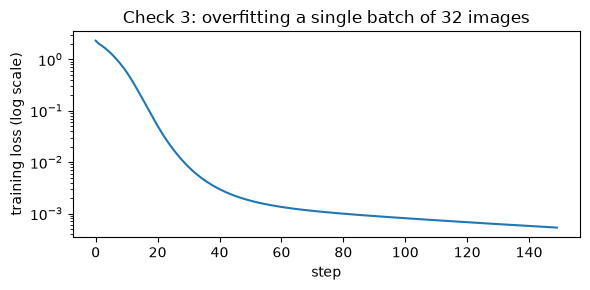

In [9]:
def overfit_one_batch(n_examples: int = 32, steps: int = 150, lr: float = 1e-3) -> list:
    """A correct pipeline must be able to memorise a handful of examples."""
    seed_everything(CFG.seed)
    tiny_model = DigitCNN(NUM_CLASSES, dropout=0.0).to(DEVICE)   # no dropout: we WANT to memorise
    optimizer = torch.optim.Adam(tiny_model.parameters(), lr=lr)
    x, y = DATASETS["train"].x[:n_examples].to(DEVICE), DATASETS["train"].y[:n_examples].to(DEVICE)
    losses = []
    for _ in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(tiny_model(x), y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    tiny_model.eval()                                            # BatchNorm uses running stats now
    with torch.inference_mode():
        train_acc = (tiny_model(x).argmax(1) == y).float().mean().item()
    print(f"Check 3  overfit one batch: loss {losses[0]:.3f} -> {losses[-1]:.4f}, "
          f"accuracy on the batch = {train_acc:.0%}")
    return losses


def input_independent_baseline(epochs: int = 3) -> float:
    """Train with all-zero inputs: the model can only learn class frequencies (~10% accuracy)."""
    seed_everything(CFG.seed)
    blind_model = DigitCNN(NUM_CLASSES, CFG.dropout).to(DEVICE)
    optimizer = torch.optim.Adam(blind_model.parameters(), lr=1e-3)
    loader = DataLoader(DATASETS["train"], batch_size=CFG.batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(CFG.seed))
    for _ in range(epochs):
        for x, y in loader:
            optimizer.zero_grad(set_to_none=True)
            F.cross_entropy(blind_model(torch.zeros_like(x).to(DEVICE)), y.to(DEVICE)).backward()
            optimizer.step()
    blind_model.eval()
    with torch.inference_mode():
        preds = blind_model(torch.zeros_like(DATASETS["val"].x).to(DEVICE)).argmax(1).cpu()
    acc = (preds == DATASETS["val"].y).float().mean().item()
    print(f"Check 4  input-independent baseline: val accuracy = {acc:.1%} (chance = {1/NUM_CLASSES:.0%})")
    return acc


overfit_losses = overfit_one_batch()
blind_acc = input_independent_baseline()

plt.figure(figsize=(6, 3))
plt.plot(overfit_losses)
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("training loss (log scale)")
plt.title("Check 3: overfitting a single batch of 32 images")
plt.tight_layout(); plt.show()

All four checks behave as expected (read the printed numbers above): the initial loss is close to ln(10), every layer receives gradients, a single batch can be memorised (loss falls by orders of magnitude, 100% accuracy on that batch), and a model that cannot see the images is stuck near chance.

Only now are we allowed to train for real.

---
## 7. The training engine

A professional training loop is split into small functions with **one job each**, which is exactly how libraries like PyTorch Lightning and the Hugging Face `Trainer` are organised internally:

| Function | Job |
|---|---|
| `build_optimizer` | AdamW with **two parameter groups**: weight decay on weights, none on biases and normalisation layers (as in the HF `Trainer` and nanoGPT) |
| `train_one_epoch` | forward → loss → backward → **gradient clipping** → optimizer step → **LR scheduler step**; returns average loss, accuracy and gradient norm |
| `evaluate` | `model.eval()` + `torch.inference_mode()`: no dropout, BatchNorm uses running statistics, no gradient bookkeeping |
| `EarlyStopping` | stops when validation loss has not improved for `patience` epochs |
| `save_checkpoint` | writes everything needed to **resume** (model, optimizer, scheduler, early-stopping state, RNG states, history, config) |

**Gradient clipping** rescales the gradient when its overall size (norm) is larger than a threshold. One bad batch then cannot throw the weights far away. It is standard in Transformers and RNN training and cheap insurance everywhere else. We also *log* the gradient norm: a sudden spike is often the first sign of trouble.

In [10]:
def build_optimizer(model: nn.Module, cfg: TrainConfig) -> torch.optim.Optimizer:
    """AdamW with weight decay only on weight matrices / conv kernels (not on biases or BatchNorm)."""
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        # 1-D tensors are biases and BatchNorm scales/shifts: decaying them only hurts
        (no_decay if param.ndim <= 1 else decay).append(param)
    groups = [{"params": decay, "weight_decay": cfg.weight_decay},
              {"params": no_decay, "weight_decay": 0.0}]
    return torch.optim.AdamW(groups, lr=cfg.max_lr)


def train_one_epoch(model, loader, optimizer, scheduler, scaler, cfg: TrainConfig) -> dict:
    """One pass over the training data. Returns average loss, accuracy, gradient norm and last LR."""
    model.train()                                            # enable dropout, BatchNorm batch statistics
    total_loss, total_correct, total_seen, grad_norms = 0.0, 0, 0, []
    amp_dtype = torch.float16 if DEVICE.type == "cuda" else torch.bfloat16
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)                # clear old gradients (set_to_none is faster)

        # Mixed precision: on a GPU this runs the forward pass in float16 (2-3x faster). Off by default.
        with torch.autocast(device_type=DEVICE.type, dtype=amp_dtype, enabled=cfg.use_amp):
            logits = model(x)
            loss = F.cross_entropy(logits, y)

        scaler.scale(loss).backward()                        # scaler is a no-op when AMP is disabled
        scaler.unscale_(optimizer)                           # un-scale BEFORE clipping, so the threshold is real
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip_norm)
        scaler.step(optimizer)                               # = optimizer.step() when AMP is disabled
        scaler.update()
        scheduler.step()                                     # OneCycle changes the LR after EVERY batch

        total_loss += loss.item() * len(y)
        total_correct += (logits.argmax(1) == y).sum().item()
        total_seen += len(y)
        grad_norms.append(grad_norm.item())
    return {"train_loss": total_loss / total_seen, "train_acc": total_correct / total_seen,
            "grad_norm": float(np.mean(grad_norms)), "lr": scheduler.get_last_lr()[0]}


@torch.inference_mode()                                      # no gradients needed: faster, less memory
def evaluate(model, loader) -> dict:
    """Loss and accuracy on a validation/test loader, plus the predicted probabilities."""
    model.eval()                                             # disable dropout, use BatchNorm running stats
    losses, probs, targets = [], [], []
    for x, y in loader:
        logits = model(x.to(DEVICE))
        losses.append(F.cross_entropy(logits, y.to(DEVICE), reduction="sum").item())
        probs.append(F.softmax(logits, dim=1).cpu())
        targets.append(y)
    probs, targets = torch.cat(probs), torch.cat(targets)
    return {"loss": sum(losses) / len(targets),
            "acc": (probs.argmax(1) == targets).float().mean().item(),
            "probs": probs.numpy(), "targets": targets.numpy()}

### Early stopping and checkpoints

- **Early stopping** watches the **validation loss**. Every time it improves, we save a `best.pt` checkpoint; if it does not improve for `patience` epochs, training stops. At the end we load `best.pt`, not the last weights.
- We save **two** checkpoints, like Lightning's `ModelCheckpoint(save_last=True)`:
  - `best.pt`: the model you will ship (best validation loss).
  - `last.pt`: the full training state after the latest epoch, so a crashed or pre-empted job (common with cheap "spot" cloud GPUs) can **resume** exactly where it stopped.
- We save the **`state_dict`** (a dictionary of tensors), not the whole Python object. This is the PyTorch-recommended way: it does not break when you rename or move your code. We load with `weights_only=True` (the safe default in recent PyTorch), which refuses to execute arbitrary pickled code from a file.
- The checkpoint contains the **config, metrics, normalisation statistics and library versions**. A weights file without this information is almost useless six months later.

Checkpoints go to a temporary folder so this notebook does not add files to the repository. In a real project this would be something like `models/digit_cnn/v1/` or a cloud bucket.

In [11]:
class EarlyStopping:
    """Stop when the monitored value (validation loss) has not improved for `patience` epochs."""

    def __init__(self, patience: int, min_delta: float = 1e-4):
        self.patience, self.min_delta = patience, min_delta
        self.best = float("inf")                  # best validation loss seen so far
        self.bad_epochs = 0                       # epochs since the last improvement

    def step(self, value: float) -> bool:
        """Returns True if this epoch is a new best."""
        if value < self.best - self.min_delta:
            self.best, self.bad_epochs = value, 0
            return True
        self.bad_epochs += 1
        return False

    @property
    def should_stop(self) -> bool:
        return self.bad_epochs >= self.patience

    def state_dict(self) -> dict:                 # so that early stopping can be resumed too
        return {"best": self.best, "bad_epochs": self.bad_epochs}

    def load_state_dict(self, state: dict) -> None:
        self.best, self.bad_epochs = state["best"], state["bad_epochs"]


def save_checkpoint(path: Path, **state) -> None:
    """Write atomically: save to a temp file first, then rename. A crash mid-write never corrupts the old file."""
    tmp_path = path.with_suffix(".tmp")
    torch.save(state, tmp_path)
    tmp_path.replace(path)


def environment_info() -> dict:
    # Plain strings only: torch.__version__ is a special TorchVersion object, and torch.load(weights_only=True)
    # refuses any non-basic Python type (that is the safety feature). So we convert it with str().
    return {"torch": str(torch.__version__), "numpy": np.__version__, "device": DEVICE.type,
            "saved_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}

---
## 8. The `fit()` function: AdamW + OneCycle + clipping + resume

`fit()` puts everything together. Key decisions:

- **AdamW** (Adam with *decoupled* weight decay) is the default optimizer in most modern deep learning code; it is forgiving and fast to converge.
- **OneCycle learning-rate schedule**: the LR warms up from small to `max_lr` during the first 30% of training, then anneals down to almost zero. Warm-up avoids unstable first steps; annealing lets the model settle into a good minimum. (Cosine decay with warm-up, used for Transformers, is very similar; see `02_optimizers.ipynb`.)
- Everything that is random is created **inside** `fit()` from the seed, so calling `fit()` twice with the same config gives the same model.
- `resume_from` reloads *all* state from `last.pt`, including the scheduler position and the random number generators, so a resumed run continues exactly as if it had never stopped.
- `stop_after_epoch` lets us **simulate a crash** in Section 10.

In [12]:
def fit(cfg: TrainConfig, ckpt_dir: Path, resume_from: Path | None = None,
        stop_after_epoch: int | None = None, verbose: bool = True) -> dict:
    """Train a DigitCNN. Returns the history (one dict per epoch). Writes best.pt and last.pt to ckpt_dir."""
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    seed_everything(cfg.seed)
    generator = torch.Generator().manual_seed(cfg.seed)              # controls the shuffle order
    loaders = make_loaders(DATASETS, cfg, generator)

    model = DigitCNN(NUM_CLASSES, cfg.dropout).to(DEVICE)
    optimizer = build_optimizer(model, cfg)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=cfg.max_lr, total_steps=cfg.max_epochs * len(loaders["train"]),
        pct_start=0.3)                                               # 30% warm-up, 70% annealing
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=cfg.use_amp and DEVICE.type == "cuda")
    stopper = EarlyStopping(cfg.patience)
    history, start_epoch = [], 1

    if resume_from is not None:                                      # ---- restore EVERYTHING ----
        ckpt = torch.load(resume_from, map_location=DEVICE, weights_only=True)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        scaler.load_state_dict(ckpt["scaler"])
        stopper.load_state_dict(ckpt["early_stopping"])
        generator.set_state(ckpt["generator_state"])                 # same shuffle order as before
        torch.set_rng_state(ckpt["torch_rng_state"])                 # same dropout masks as before
        history, start_epoch = ckpt["history"], ckpt["epoch"] + 1
        log.info("Resumed from %s at epoch %d", resume_from.name, start_epoch)

    for epoch in range(start_epoch, cfg.max_epochs + 1):
        t0 = time.perf_counter()
        train_stats = train_one_epoch(model, loaders["train"], optimizer, scheduler, scaler, cfg)
        val = evaluate(model, loaders["val"])
        is_best = stopper.step(val["loss"])
        row = {"epoch": epoch, **train_stats, "val_loss": val["loss"], "val_acc": val["acc"],
               "seconds": time.perf_counter() - t0}
        history.append(row)

        common = {"epoch": epoch, "config": asdict(cfg), "history": history, "env": environment_info(),
                  "normalization": {"mean": NORM_MEAN, "std": NORM_STD}, "class_names": CLASS_NAMES}
        if is_best:   # the model to ship: weights only + everything needed to use it
            save_checkpoint(ckpt_dir / "best.pt", model=model.state_dict(),
                            metrics={"val_loss": val["loss"], "val_acc": val["acc"]}, **common)
        # the full training state, overwritten every epoch, for resuming
        save_checkpoint(ckpt_dir / "last.pt", model=model.state_dict(), optimizer=optimizer.state_dict(),
                        scheduler=scheduler.state_dict(), scaler=scaler.state_dict(),
                        early_stopping=stopper.state_dict(), generator_state=generator.get_state(),
                        torch_rng_state=torch.get_rng_state(), **common)

        if verbose and (epoch % 5 == 0 or epoch == 1 or is_best and epoch > cfg.max_epochs - 5):
            log.info("epoch %2d | train loss %.4f acc %.3f | val loss %.4f acc %.3f | lr %.2e | "
                     "grad-norm %.2f%s", epoch, row["train_loss"], row["train_acc"], row["val_loss"],
                     row["val_acc"], row["lr"], row["grad_norm"], "  <- best" if is_best else "")
        if stopper.should_stop:
            log.info("Early stopping at epoch %d (no val-loss improvement for %d epochs)", epoch, cfg.patience)
            break
        if stop_after_epoch is not None and epoch >= stop_after_epoch:
            log.warning("Simulated crash after epoch %d!", epoch)
            break
    return {"history": history, "model": model}

---
## 9. Train the model and read the learning curves

In [13]:
RUN_DIR = Path(tempfile.mkdtemp(prefix="digit_cnn_run_"))     # in real life: models/digit_cnn/v1/
t_start = time.perf_counter()
result = fit(CFG, RUN_DIR / "main")
history = pd.DataFrame(result["history"])
print(f"\nTrained {len(history)} epochs in {time.perf_counter() - t_start:.1f}s "
      f"({history['seconds'].mean():.2f}s per epoch on {DEVICE.type})")

best_row = history.loc[history["val_loss"].idxmin()]
print(f"Best epoch: {int(best_row.epoch)} | val loss {best_row.val_loss:.4f} | val acc {best_row.val_acc:.3f}")
print("Checkpoint files:", sorted(p.name for p in (RUN_DIR / "main").iterdir()))

2026-10-21 16:30:40,875 | INFO | epoch  1 | train loss 2.2478 acc 0.188 | val loss 2.1846 acc 0.444 | lr 1.70e-04 | grad-norm 2.55  <- best


2026-10-21 16:30:42,551 | INFO | epoch  5 | train loss 0.3810 acc 0.911 | val loss 0.1872 acc 0.956 | lr 1.20e-03 | grad-norm 2.23  <- best


2026-10-21 16:30:44,450 | INFO | epoch 10 | train loss 0.0698 acc 0.983 | val loss 0.0422 acc 0.983 | lr 2.82e-03 | grad-norm 1.21  <- best


2026-10-21 16:30:48,546 | INFO | epoch 15 | train loss 0.0394 acc 0.984 | val loss 0.0733 acc 0.983 | lr 2.91e-03 | grad-norm 1.01


2026-10-21 16:30:52,396 | INFO | epoch 20 | train loss 0.0117 acc 0.998 | val loss 0.0281 acc 0.986 | lr 2.43e-03 | grad-norm 0.49


2026-10-21 16:30:55,195 | INFO | epoch 25 | train loss 0.0108 acc 0.995 | val loss 0.0178 acc 0.994 | lr 1.66e-03 | grad-norm 0.39  <- best


2026-10-21 16:30:57,659 | INFO | epoch 30 | train loss 0.0057 acc 0.999 | val loss 0.0159 acc 0.997 | lr 8.40e-04 | grad-norm 0.22  <- best


2026-10-21 16:30:59,928 | INFO | epoch 35 | train loss 0.0034 acc 0.999 | val loss 0.0152 acc 0.994 | lr 2.25e-04 | grad-norm 0.19


2026-10-21 16:31:02,213 | INFO | epoch 40 | train loss 0.0014 acc 1.000 | val loss 0.0162 acc 0.997 | lr 4.47e-08 | grad-norm 0.08



Trained 40 epochs in 21.8s (0.53s per epoch on cpu)
Best epoch: 33 | val loss 0.0118 | val acc 0.994
Checkpoint files: ['best.pt', 'last.pt']


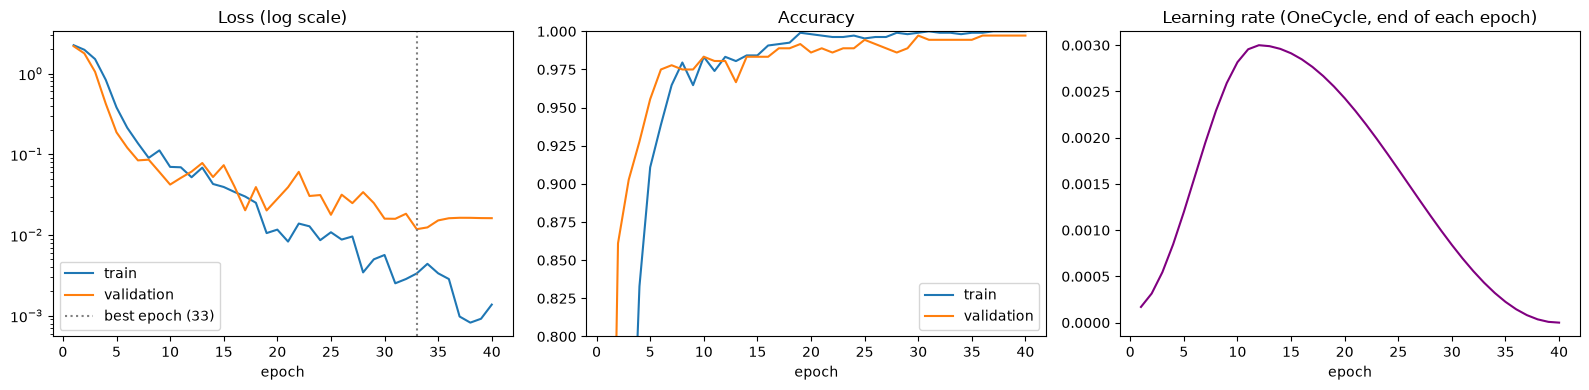

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(history.epoch, history.train_loss, label="train")
axes[0].plot(history.epoch, history.val_loss, label="validation")
axes[0].axvline(best_row.epoch, color="grey", ls=":", label=f"best epoch ({int(best_row.epoch)})")
axes[0].set_yscale("log"); axes[0].set_title("Loss (log scale)"); axes[0].legend()
axes[1].plot(history.epoch, history.train_acc, label="train")
axes[1].plot(history.epoch, history.val_acc, label="validation")
axes[1].set_ylim(0.8, 1.0); axes[1].set_title("Accuracy"); axes[1].legend()
axes[2].plot(history.epoch, history.lr, color="purple")
axes[2].set_title("Learning rate (OneCycle, end of each epoch)")
for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()

**How to read learning curves like a professional:**
- **Both losses go down together** at the start: the model is learning general patterns.
- **Train loss below validation loss** is normal. A *growing* gap with validation loss going **up** again means **overfitting**; early stopping and the best checkpoint protect us from it.
- Training accuracy is measured **with dropout on** (the model is handicapped during training), which is why it can be *lower* than validation accuracy early on. This confuses many beginners.
- The learning rate rises (warm-up) and then decays towards zero. Notice the validation loss gets *worse* around the LR peak (epoch ~15) and reaches its best value at epoch 33, in the low-LR phase. In this run early stopping never triggered (patience 8, and the best epoch was late), so the full 40 epochs ran and `best.pt` holds epoch 33.
- If the curves were flat from the start, go back to the sanity checks; if the loss exploded to `nan`, lower `max_lr` or check the gradient-norm log.

---
## 10. Crash and resume: proving the pipeline is reproducible

Long training jobs get interrupted (out-of-memory, a pre-empted spot instance, a power cut). A professional pipeline can **resume** from `last.pt` and end up with **exactly the same model** as an uninterrupted run.

To prove it we run a short 12-epoch experiment twice:
1. **Uninterrupted:** 12 epochs in one go.
2. **Interrupted:** "crash" after epoch 5, then start a fresh `fit()` that resumes from `last.pt` and continues to epoch 12.

If the checkpoint stores *all* state (weights, optimizer moments, LR-scheduler position, early-stopping counters, the shuffle generator and the dropout RNG) the two histories are identical.

In [15]:
short_cfg = replace(CFG, max_epochs=12)                       # same settings, shorter run

uninterrupted = pd.DataFrame(fit(short_cfg, RUN_DIR / "uninterrupted", verbose=False)["history"])

fit(short_cfg, RUN_DIR / "interrupted", stop_after_epoch=5, verbose=False)        # crashes after epoch 5
resumed = pd.DataFrame(fit(short_cfg, RUN_DIR / "interrupted",
                           resume_from=RUN_DIR / "interrupted" / "last.pt", verbose=False)["history"])

cols = ["epoch", "train_loss", "val_loss", "val_acc"]
comparison = uninterrupted[cols].merge(resumed[cols], on="epoch", suffixes=("_uninterrupted", "_resumed"))
max_diff = (comparison["val_loss_uninterrupted"] - comparison["val_loss_resumed"]).abs().max()
print(comparison.tail(4).round(6).to_string(index=False))
print(f"\nLargest val-loss difference over all 12 epochs: {max_diff:.2e}")

2026-10-21 16:31:11,737 | WARNING | Simulated crash after epoch 5!


2026-10-21 16:31:11,768 | INFO | Resumed from last.pt at epoch 6


 epoch  train_loss_uninterrupted  val_loss_uninterrupted  val_acc_uninterrupted  train_loss_resumed  val_loss_resumed  val_acc_resumed
     9                  0.038839                0.033140               0.991667            0.038839          0.033140         0.991667
    10                  0.025101                0.022724               0.991667            0.025101          0.022724         0.991667
    11                  0.023347                0.022537               0.988889            0.023347          0.022537         0.988889
    12                  0.020066                0.022753               0.986111            0.020066          0.022753         0.986111

Largest val-loss difference over all 12 epochs: 0.00e+00


The resumed run reproduces the uninterrupted one (the largest difference printed above is zero or at floating-point noise level). Try removing `generator.set_state(...)` or the scheduler restore from `fit()` and re-run this cell: the curves will diverge. Those are exactly the bugs that make "resumed" production runs quietly worse.

---
## 11. Final evaluation on the test set against baselines

Now, **once**, we open the drawer. We load the **best** checkpoint (not the last weights) and evaluate it on the test set.

A neural network is only worth its complexity if it beats simpler models **on the same split**. Our baselines:
- **Dummy** (always predicts the most common class): the absolute floor.
- **Logistic regression** on the 64 normalised pixels: the model the team already has.
- **RBF Support Vector Machine**: a strong classical model, famous for doing very well on exactly this dataset.

Baselines are trained on the **training set only**, the same data the CNN learned from (the CNN additionally used validation data to pick its epoch, which is the job of the validation set).

With only 360 test images, one mistake changes accuracy by 0.28 percentage points. So we also report a **95% bootstrap confidence interval**: resample the test set 1,000 times and look at how much the accuracy moves.

In [16]:
best_ckpt = torch.load(RUN_DIR / "main" / "best.pt", map_location=DEVICE, weights_only=True)
best_model = DigitCNN(NUM_CLASSES, best_ckpt["config"]["dropout"]).to(DEVICE)
best_model.load_state_dict(best_ckpt["model"])
print(f"Loaded best checkpoint from epoch {best_ckpt['epoch']} (val loss {best_ckpt['metrics']['val_loss']:.4f})")

test_loader = make_loaders(DATASETS, CFG, torch.Generator().manual_seed(0))["test"]
test_out = evaluate(best_model, test_loader)
y_test, cnn_pred = test_out["targets"], test_out["probs"].argmax(1)

# Baselines on flat, identically-normalised pixels
flat_norm = ((images - NORM_MEAN) / NORM_STD).reshape(len(images), -1)
baselines = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "SVM (RBF kernel)": SVC(),
}
predictions = {}
for name, clf in baselines.items():
    clf.fit(flat_norm[idx_train], labels[idx_train])
    predictions[name] = clf.predict(flat_norm[idx_test])
predictions["CNN (ours, best checkpoint)"] = cnn_pred


def bootstrap_accuracy_ci(y_true, y_pred, n_boot: int = 1000, seed: int = 0) -> tuple:
    rng = np.random.default_rng(seed)
    correct = (y_true == y_pred).astype(float)
    samples = [correct[rng.integers(0, len(correct), len(correct))].mean() for _ in range(n_boot)]
    return np.percentile(samples, 2.5), np.percentile(samples, 97.5)


rows = []
for name, pred in predictions.items():
    low, high = bootstrap_accuracy_ci(y_test, pred)
    rows.append({"model": name, "test_accuracy": accuracy_score(y_test, pred),
                 "95% CI": f"[{low:.3f}, {high:.3f}]", "macro_F1": f1_score(y_test, pred, average="macro"),
                 "errors (of 360)": int((pred != y_test).sum())})
results_table = pd.DataFrame(rows).round(4)
results_table

Loaded best checkpoint from epoch 33 (val loss 0.0118)


,model,test_accuracy,95% CI,macro_F1,errors (of 360)
0,Dummy (most frequent),0.1000,"[0.069, 0.133]",0.0182,324
1,Logistic regression,0.9583,"[0.936, 0.975]",0.9579,15
2,SVM (RBF kernel),0.9917,"[0.981, 1.000]",0.9916,3
3,"CNN (ours, best checkpoint)",0.9944,"[0.986, 1.000]",0.9944,2


**Reading the results honestly:**
- The CNN makes **2 mistakes out of 360** (99.4%). The team's current logistic regression makes **15** (95.8%), and the two confidence intervals do not overlap: success criterion 1 is met.
- But the classical **RBF SVM** makes **3 mistakes**: one image apart from the CNN, and the confidence intervals overlap almost completely. On a dataset this small and simple, a well-chosen classical model is **as good as** the neural network, and cheaper to train and run. This is a common real-world finding, and you should report it instead of hiding it.
- So why do companies still build pipelines like this one? Because the advantage of neural networks grows with **bigger images, more data, data augmentation and pretrained models** (see `06_Computer_Vision/`), where SVMs stop scaling. The pipeline we built here is exactly the one you would reuse there.
- **Red-flag check:** the CNN's test accuracy (99.4%) is in line with its validation accuracy (99.4%), so there is no sign that we overfitted to the validation set.

---
## 12. Error analysis and the business decision (auto-accept threshold)

Two questions a product owner will ask:

1. **Which mistakes does the model make?** We list the most frequent confusions and look at the misclassified scans. Often some "errors" are actually unreadable or mislabelled images. That is valuable feedback for the labelling team.
2. **How many digits can we automate safely?** The model outputs a probability. We auto-accept a digit only if its highest probability is above a **confidence threshold**; the rest go to a human. A higher threshold means fewer errors but also less automation.

We choose the threshold on the **validation** set (target: error rate of accepted digits ≤ 0.5%) and then report what happens on the **test** set.

Mistakes on the test set (true -> predicted : count):
  1 -> 7 : 1
  0 -> 4 : 1


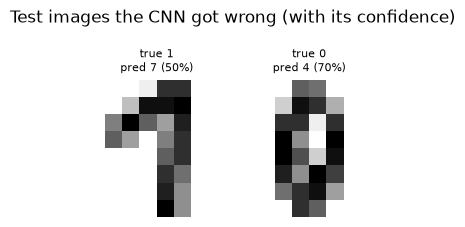

In [17]:
# 1. Most frequent confusions on the test set
cm = confusion_matrix(y_test, cnn_pred)
np.fill_diagonal(cm, 0)                                     # keep only the mistakes
pairs = [(cm[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm[i, j] > 0]
print("Mistakes on the test set (true -> predicted : count):")
for count, true_digit, pred_digit in sorted(pairs, reverse=True):
    print(f"  {true_digit} -> {pred_digit} : {count}")

# Show the misclassified scans
wrong = np.where(cnn_pred != y_test)[0]
fig, axes = plt.subplots(1, max(len(wrong), 1), figsize=(1.6 * max(len(wrong), 1), 2.2), squeeze=False)
for ax, i in zip(axes[0], wrong):
    ax.imshow(images[idx_test[i]], cmap="gray_r")
    ax.set_title(f"true {y_test[i]}\npred {cnn_pred[i]} ({test_out['probs'][i].max():.0%})", fontsize=8)
    ax.axis("off")
plt.suptitle("Test images the CNN got wrong (with its confidence)", y=1.05)
plt.tight_layout(); plt.show()

In [18]:
val_out = evaluate(best_model, make_loaders(DATASETS, CFG, torch.Generator())["val"])


def automation_table(out: dict, thresholds) -> pd.DataFrame:
    confidence, pred = out["probs"].max(1), out["probs"].argmax(1)
    rows = []
    for t in thresholds:
        accepted = confidence >= t
        errors = int(((pred != out["targets"]) & accepted).sum())
        rows.append({"threshold": t, "automated_%": 100 * accepted.mean(),
                     "errors_in_automated": errors,
                     "error_rate_automated_%": 100 * errors / max(accepted.sum(), 1)})
    return pd.DataFrame(rows)


THRESHOLDS = [0.0, 0.5, 0.8, 0.9, 0.95, 0.99]
val_table = automation_table(val_out, THRESHOLDS)
ok = val_table[val_table["error_rate_automated_%"] <= 0.5]
chosen_threshold = float(ok["threshold"].min()) if len(ok) else 0.99     # lowest threshold meeting the target
print("Validation set:")
print(val_table.round(2).to_string(index=False))
print(f"\nChosen auto-accept threshold (val error ≤ 0.5%): {chosen_threshold}")

test_row = automation_table(test_out, [chosen_threshold]).iloc[0]
n_test = len(y_test)
manual_cost = n_test * 0.05                                                   # everything typed by hand
model_cost = (1 - test_row["automated_%"] / 100) * n_test * 0.05 + test_row["errors_in_automated"] * 5.0
print(f"\nTest set at threshold {chosen_threshold}: automated {test_row['automated_%']:.1f}% of digits, "
      f"{int(test_row['errors_in_automated'])} wrong auto-accepted digits "
      f"({test_row['error_rate_automated_%']:.2f}%)")
print(f"Cost for these {n_test} digits: all manual ${manual_cost:.2f}  vs  model + humans ${model_cost:.2f}")

Validation set:
 threshold  automated_%  errors_in_automated  error_rate_automated_%
      0.00       100.00                    2                    0.56
      0.50       100.00                    2                    0.56
      0.80        99.17                    1                    0.28
      0.90        98.33                    0                    0.00
      0.95        98.33                    0                    0.00
      0.99        96.11                    0                    0.00

Chosen auto-accept threshold (val error ≤ 0.5%): 0.8

Test set at threshold 0.8: automated 99.4% of digits, 0 wrong auto-accepted digits (0.00%)
Cost for these 360 digits: all manual $18.00  vs  model + humans $0.10


**What this means for the business:**
- The CNN's two test mistakes (a `1` read as `7`, a `0` read as `4`) are exactly the kind of confusions a human would also hesitate on with such blurry scans.
- With the threshold chosen on validation (0.8), the model auto-accepts **99.4% of the test digits (358 of 360)** with **0 wrong auto-accepted digits**: the two digits it sent to a human are precisely its two mistakes. Data-entry cost for these 360 digits drops from **$18.00 to $0.10**.
- ⚠️ **Don't over-promise.** "0 errors in 358 digits" does **not** mean the error rate is zero. A handy rule ("rule of three"): with 0 errors in *n* trials, the 95% upper bound of the true error rate is about **3/n**, here 3/358 ≈ **0.8%**, which is *above* our 0.5% target. To prove the target you need more labelled test data, or a **shadow-mode** period in production where humans still check a sample of auto-accepted digits.

---
## 13. How much do results depend on the seed?

A single training run is **one sample** from a random process. Before telling your manager "the new model is 0.5% better", check how much the result moves when *only the seed* changes. Research papers and careful teams report **mean ± standard deviation over several seeds**.

We retrain with two more seeds (same config, same split) and evaluate each best checkpoint on the test set.

In [19]:
seed_rows = [{"seed": CFG.seed, "best_epoch": int(best_ckpt["epoch"]),
              "val_acc": best_ckpt["metrics"]["val_acc"], "test_acc": accuracy_score(y_test, cnn_pred)}]
for seed in [1, 2]:
    run = fit(replace(CFG, seed=seed), RUN_DIR / f"seed_{seed}", verbose=False)
    ckpt = torch.load(RUN_DIR / f"seed_{seed}" / "best.pt", map_location=DEVICE, weights_only=True)
    m = DigitCNN(NUM_CLASSES, CFG.dropout).to(DEVICE)
    m.load_state_dict(ckpt["model"])
    out = evaluate(m, test_loader)
    seed_rows.append({"seed": seed, "best_epoch": int(ckpt["epoch"]), "val_acc": ckpt["metrics"]["val_acc"],
                      "test_acc": float((out["probs"].argmax(1) == out["targets"]).mean())})
seeds_df = pd.DataFrame(seed_rows)
print(seeds_df.round(4).to_string(index=False))
print(f"\nTest accuracy over seeds: {seeds_df.test_acc.mean():.4f} ± {seeds_df.test_acc.std():.4f}")

2026-10-21 16:31:33,340 | INFO | Early stopping at epoch 40 (no val-loss improvement for 8 epochs)


2026-10-21 16:31:45,349 | INFO | Early stopping at epoch 26 (no val-loss improvement for 8 epochs)


 seed  best_epoch  val_acc  test_acc
   42          33   0.9944    0.9944
    1          32   0.9889    0.9944
    2          18   0.9889    0.9861

Test accuracy over seeds: 0.9917 ± 0.0048


**What the seeds tell us:**
- Only by changing the seed, test accuracy moves between **98.6% and 99.4%** (mean 99.2% ± 0.5 points). So a single run that is 0.5 points better than another proves nothing; compare **averages over seeds**.
- **Seed 2 is a useful lesson:** early stopping halted it at epoch 26 (best epoch 18) while the OneCycle learning rate was still high, so the model never got the low-LR "settling" phase at the end, and it has the lowest test accuracy. Early stopping and LR schedules interact: with a schedule that decays to zero, teams often use a larger `patience`, or simply train the full schedule and keep the best checkpoint. In the main run (seed 42) early stopping never triggered, because the validation loss kept improving until epoch 33.

---
## 14. Load the checkpoint like production does

The serving code lives in a different program and must not depend on notebook variables. It needs only the **checkpoint file** and the **model class**. Everything else (normalisation statistics, class names, config) comes *from the checkpoint*. Note the input validation: a production function must refuse garbage instead of silently returning a confident wrong answer.

(Exporting the model to ONNX/TorchScript, quantization and latency benchmarks are covered in the companion notebook `17_industry_model_export_and_inference.ipynb`.)

In [20]:
class DigitPredictor:
    """Loads best.pt once and predicts digits from raw 8x8 scans (values 0..16)."""

    def __init__(self, checkpoint_path: Path, device: torch.device = torch.device("cpu")):
        ckpt = torch.load(checkpoint_path, map_location=device, weights_only=True)
        self.model = DigitCNN(len(ckpt["class_names"]), ckpt["config"]["dropout"]).to(device)
        self.model.load_state_dict(ckpt["model"])
        self.model.eval()                                   # NEVER forget this before inference
        self.mean, self.std = ckpt["normalization"]["mean"], ckpt["normalization"]["std"]
        self.class_names, self.device = ckpt["class_names"], device
        self.version = f"epoch{ckpt['epoch']}-torch{ckpt['env']['torch']}"

    def predict(self, scans: np.ndarray) -> list[dict]:
        scans = np.asarray(scans, dtype=np.float32)
        if scans.ndim == 2:                                 # a single image -> batch of one
            scans = scans[None]
        if scans.shape[1:] != (8, 8):
            raise ValueError(f"expected images of shape (8, 8), got {scans.shape[1:]}")
        if not np.isfinite(scans).all() or scans.min() < 0 or scans.max() > 16:
            raise ValueError("pixel values must be finite and in [0, 16]")
        x = torch.from_numpy((scans - self.mean) / self.std).unsqueeze(1).to(self.device)
        with torch.inference_mode():
            probs = F.softmax(self.model(x), dim=1).cpu().numpy()
        return [{"digit": self.class_names[p.argmax()], "confidence": round(float(p.max()), 4),
                 "auto_accept": bool(p.max() >= chosen_threshold), "model_version": self.version}
                for p in probs]


predictor = DigitPredictor(RUN_DIR / "main" / "best.pt")
print(predictor.predict(images[idx_test[:3]]), "\ntrue labels:", labels[idx_test[:3]].tolist())
try:
    predictor.predict(np.full((8, 8), 255.0))               # a caller sends 0..255 pixels by mistake
except ValueError as err:
    print("Rejected bad input ->", err)

[{'digit': '5', 'confidence': 1.0, 'auto_accept': True, 'model_version': 'epoch33-torch2.12.1+cpu'}, {'digit': '2', 'confidence': 1.0, 'auto_accept': True, 'model_version': 'epoch33-torch2.12.1+cpu'}, {'digit': '8', 'confidence': 1.0, 'auto_accept': True, 'model_version': 'epoch33-torch2.12.1+cpu'}] 
true labels: [5, 2, 8]
Rejected bad input -> pixel values must be finite and in [0, 16]


---
## 15. Automated tests

Professional training code is tested like any other software (normally in `tests/` with `pytest`, run in CI; see `15_MLOps/07_testing_in_ml/`). Small, fast tests catch the classic deep learning bugs:

In [21]:
def test_checkpoint_roundtrip_gives_identical_predictions():
    """Loading best.pt must reproduce the in-memory predictions exactly."""
    restored = np.array([r["digit"] for r in predictor.predict(images[idx_test])]).astype(int)
    assert (restored == cnn_pred).all()


def test_eval_mode_is_deterministic():
    """In eval mode dropout is off: the same input must give the same output twice."""
    x = DATASETS["test"].x[:16].to(DEVICE)
    best_model.eval()
    with torch.inference_mode():
        assert torch.equal(best_model(x), best_model(x))


def test_output_shape_and_probabilities():
    x = DATASETS["test"].x[:5].to(DEVICE)
    with torch.inference_mode():
        probs = F.softmax(best_model(x), dim=1)
    assert probs.shape == (5, NUM_CLASSES)
    assert torch.allclose(probs.sum(1), torch.ones(5))


def test_no_leakage_between_splits():
    """The same scan index must never be in two splits."""
    assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test))


def test_quality_gate():
    """Never ship a model that is not clearly better than the existing logistic-regression model."""
    assert accuracy_score(y_test, cnn_pred) >= accuracy_score(y_test, predictions["Logistic regression"])


for test in [test_checkpoint_roundtrip_gives_identical_predictions, test_eval_mode_is_deterministic,
             test_output_shape_and_probabilities, test_no_leakage_between_splits, test_quality_gate]:
    test()
    print(f"PASSED  {test.__name__}")

shutil.rmtree(RUN_DIR, ignore_errors=True)                 # clean up the temporary checkpoints

PASSED  test_checkpoint_roundtrip_gives_identical_predictions
PASSED  test_eval_mode_is_deterministic
PASSED  test_output_shape_and_probabilities
PASSED  test_no_leakage_between_splits
PASSED  test_quality_gate


---
## 16. GPUs, mixed precision and frameworks

This notebook runs on a CPU, but the code is already **device-agnostic**: on a machine with a GPU, `get_device()` returns `cuda` and nothing else needs to change. When you scale up, these are the next levers (in rough order of how often they are used):

| Technique | What it does | How to turn it on here |
|---|---|---|
| **GPU** | 10-100x faster matrix maths | automatic via `get_device()`; keep `pin_memory=True`, `non_blocking=True` |
| **Mixed precision (AMP)** | runs most maths in 16-bit floats: ~2x faster, half the activation memory | `TrainConfig(use_amp=True)`. On NVIDIA GPUs `float16` needs the `GradScaler` (already in our loop) to avoid tiny gradients underflowing to zero; on A100/H100 GPUs prefer `bfloat16`, which needs no scaler |
| **More DataLoader workers** | decode/augment images in parallel | `num_workers=4..8`, `persistent_workers=True`, plus a `worker_init_fn` for seeding |
| **`torch.compile(model)`** | compiles the model into fused kernels, often 1.3-2x faster on GPU | one line after creating the model; check the speed-up on your own model |
| **Gradient accumulation** | simulates a bigger batch when memory is short | call `optimizer.step()` every *k* batches; divide the loss by *k* |
| **Distributed training (DDP/FSDP)** | many GPUs | see `11_distributed_training.ipynb` |

**Determinism on GPU** costs some speed (`use_deterministic_algorithms`, `cudnn.benchmark=False`). Many teams keep it on while developing and debugging, and turn `cudnn.benchmark=True` back on for the final, long runs.

### You will rarely write this loop from scratch at work... but you must understand it

Frameworks package exactly these pieces so that you don't re-implement them in every project:

| What we wrote | PyTorch Lightning | Hugging Face `Trainer` |
|---|---|---|
| `TrainConfig` | `LightningModule.hparams` / CLI config | `TrainingArguments` |
| `train_one_epoch` body | `training_step()` | `compute_loss()` (built in) |
| `build_optimizer` + OneCycle | `configure_optimizers()` | `optim=`, `lr_scheduler_type=`, `warmup_ratio=`, `weight_decay=` |
| gradient clipping | `Trainer(gradient_clip_val=1.0)` | `max_grad_norm=1.0` |
| `EarlyStopping` | `EarlyStopping` callback | `EarlyStoppingCallback` |
| `best.pt` / `last.pt` | `ModelCheckpoint(monitor="val_loss", save_last=True)` | `save_strategy=`, `load_best_model_at_end=True` |
| `resume_from=` | `trainer.fit(ckpt_path="last")` | `trainer.train(resume_from_checkpoint=True)` |
| `use_amp` | `Trainer(precision="16-mixed")` | `fp16=True` / `bf16=True` |
| `seed_everything` | `lightning.seed_everything(42)` | `seed=42` |

When a framework run behaves strangely, knowing what happens inside (this notebook) is what lets you debug it.

---
## 17. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Central config | frozen `TrainConfig` saved inside each checkpoint | every training repo; Hydra / Lightning CLI / `TrainingArguments` |
| Seeding + determinism | `seed_everything`, `use_deterministic_algorithms` | debugging, audits, regulated industries |
| Look at the data first | class balance, duplicates, images, the batch "just before the net" | Karpathy's recipe step 1 |
| Train-only normalisation | mean/std from train, stored in the checkpoint | avoids leakage and training/serving skew |
| Sanity checks | loss@init ≈ ln(C), gradient flow, overfit one batch, blind baseline | catching bugs in minutes instead of days |
| AdamW + parameter groups | no weight decay on biases/norms | Transformers, HF `Trainer`, nanoGPT |
| OneCycle / warm-up + decay | LR schedule stepped per batch | nearly every modern training run |
| Gradient clipping + grad-norm logging | `clip_grad_norm_` | Transformers, RNNs, RL |
| Early stopping + best checkpoint | `best.pt` by validation loss | Lightning `ModelCheckpoint`, HF `load_best_model_at_end` |
| Resumable checkpoints | `last.pt` with optimizer, scheduler, RNG states | spot/pre-emptible GPUs, long runs |
| Baselines + CI | dummy, logistic regression, SVM, bootstrap interval | deciding if DL is worth it |
| Seed variance | 3 seeds, mean ± std | honest model comparisons |
| Business threshold | auto-accept confidence picked on validation | human-in-the-loop systems |
| Tests | round-trip, determinism, leakage, quality gate | CI for ML code |

### Practice exercises
1. Set `max_lr=3e-2` (10x higher) and re-run Section 9. What happens to the gradient-norm log and the curves? Then try `grad_clip_norm=1e9` (clipping effectively off).
2. Replace `OneCycleLR` with `CosineAnnealingLR` plus a linear warm-up (`torch.optim.lr_scheduler.SequentialLR`). Does the best validation loss change by more than the seed variance from Section 13?
3. Add **data augmentation** for training only (small random shifts of the 8x8 image with `torch.roll`). Why must augmentation never be applied to the validation/test sets?
4. Remove `torch_rng_state` from the checkpoint and re-run Section 10. Which epochs differ and why?
5. Rewrite `fit()` as a `lightning.LightningModule` and compare the amount of code.

### Resources (checked)
- Andrej Karpathy, *A Recipe for Training Neural Networks*: https://karpathy.github.io/2019/04/25/recipe/
- PyTorch tutorial, *Saving and Loading Models* (state_dict, general checkpoints, `weights_only`): https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html
- PyTorch notes, *Reproducibility*: https://docs.pytorch.org/docs/stable/notes/randomness.html
- PyTorch *Automatic Mixed Precision* docs: https://docs.pytorch.org/docs/stable/amp.html
- PyTorch *Performance Tuning Guide*: https://docs.pytorch.org/tutorials/recipes/recipes/tuning_guide.html
- PyTorch Lightning, checkpointing and early stopping: https://lightning.ai/docs/pytorch/stable/common/checkpointing_basic.html
- Hugging Face `Trainer` and `TrainingArguments`: https://huggingface.co/docs/transformers/main_classes/trainer
- Karpathy's nanoGPT `train.py` (a compact, real training loop with AdamW parameter groups, warm-up + cosine, clipping, checkpoint/resume): https://github.com/karpathy/nanoGPT
- Made With ML (Goku Mohandas), production ML course incl. training and evaluation: https://madewithml.com/ and https://github.com/GokuMohandas/Made-With-ML

### Related notebooks in this repo
- Theory of layers, losses, initialisation, BatchNorm, dropout: [`01_neural_network_fundamentals.ipynb`](01_neural_network_fundamentals.ipynb)
- Optimizers, LR schedules and gradient clipping explained: [`02_optimizers.ipynb`](02_optimizers.ipynb)
- CNN building blocks: [`03_cnn.ipynb`](03_cnn.ipynb)
- Mixed precision and multi-GPU training: [`11_distributed_training.ipynb`](11_distributed_training.ipynb)
- Neural nets vs gradient boosting on tables: [`14_tabular_deep_learning.ipynb`](14_tabular_deep_learning.ipynb)
- Next step, shipping this kind of model: [`17_industry_model_export_and_inference.ipynb`](17_industry_model_export_and_inference.ipynb)
- Experiment tracking (log these runs to MLflow): [`../15_MLOps/01_experiment_tracking/`](../15_MLOps/01_experiment_tracking/)
- Testing ML code: [`../15_MLOps/07_testing_in_ml/`](../15_MLOps/07_testing_in_ml/)